# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Sherlock Chen, Henry Fong, Edward Christopher

**Date:** 11/9/2026

<class 'pandas.DataFrame'>
RangeIndex: 16814 entries, 0 to 16813
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   sale_date                    16814 non-null  str  
 1   sale_price                   16814 non-null  int64
 2   house_square_feet            16814 non-null  int64
 3   attic_finished_square_feet   16814 non-null  int64
 4   basement_square_feet         16814 non-null  int64
 5   attached_garage_square_feet  16814 non-null  int64
 6   detached_garage_square_feet  16814 non-null  int64
 7   fireplaces                   16814 non-null  int64
 8   hvac_description             16807 non-null  str  
 9   exterior                     16813 non-null  str  
 10  interior                     16807 non-null  str  
 11  stories                      16814 non-null  int64
 12  roof_cover                   16806 non-null  str  
 13  year_built                   16814 non-null  int64
 14  b

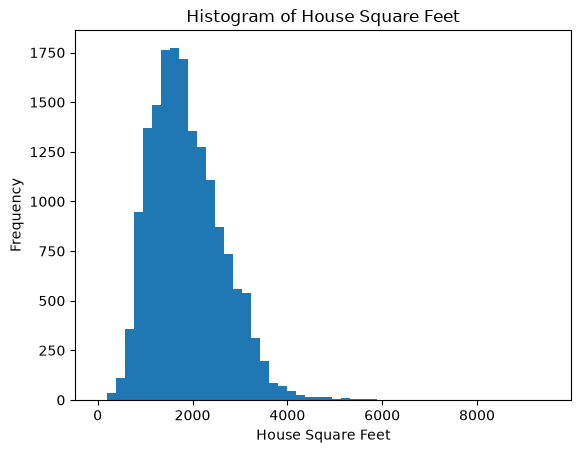

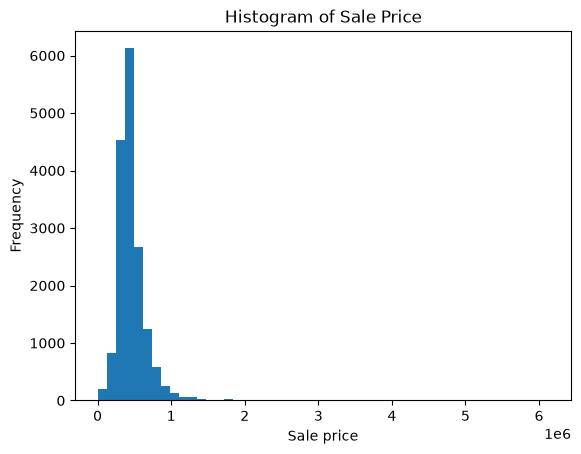

Model 1 Results:
Train RMSE: 200769.4407234562 and Train R2: 0.29058927620246167
Test RMSE:  185993.0860541432 and Test R2:  0.326660354485769
Model 2 Results:
Train RMSE: 166972.26958327874 and Train R2: 0.5093280500168363
Test RMSE:  159539.5011219844 and Test R2:  0.5045759964888721


In [ ]:
# Your Phase 1 solution to the problem goes here.

# Question 1
import pandas as pd
import matplotlib.pyplot as plt

path = "data/pierce_county_house_sales.csv"
df = pd.read_csv(path)

# Overview of dataset
df.info()
df.describe()

# Check for null values
print(df.isnull().sum())
print(df[df.isnull().any(axis=1)])

# Histograms for visualization
house_square_feet = df["house_square_feet"]
plt.hist(house_square_feet, bins=50)
plt.title("Histogram of House Square Feet")
plt.xlabel("House Square Feet")
plt.ylabel("Frequency")
plt.show()

sale_price = df["sale_price"]
plt.hist(sale_price, bins=50)
plt.title("Histogram of Sale Price")
plt.xlabel("Sale price")
plt.ylabel("Frequency")
plt.show()

# Question 2

# One-hot encode categorical variables
lst = ["hvac_description", "exterior", "interior", "roof_cover", "waterfront_type", "view_quality", "utility_sewer"]
df_encoded = pd.get_dummies(df, columns=lst, drop_first=True)

# Question 3
from sklearn.model_selection import train_test_split

# Define features and targets and split
X = df_encoded.drop(columns=["sale_price", "sale_date"])
y = df_encoded["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=65
)

# Question 4
from sklearn.linear_model import LinearRegression
import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Model 1
features_1 = ["house_square_feet", "bedrooms", "bathrooms"]
X_train_1 = X_train[features_1]
X_test_1 = X_test[features_1]

model1 = LinearRegression()
model1.fit(X_train_1, y_train)

train_pred_1 = model1.predict(X_train_1)
train_rmse_1 = np.sqrt(mean_squared_error(y_train, train_pred_1))
train_r2_1 = r2_score(y_train, train_pred_1)

test_pred_1 = model1.predict(X_test_1)
test_rmse_1 = np.sqrt(mean_squared_error(y_test, test_pred_1))
test_r2_1 = r2_score(y_test, test_pred_1)

print("Model 1 Results:")
print(f"Train RMSE: {train_rmse_1} and Train R2: {train_r2_1}")
print(f"Test RMSE:  {test_rmse_1} and Test R2:  {test_r2_1}")

# Model 2
model2 = LinearRegression()
model2.fit(X_train, y_train)

train_pred_2 = model2.predict(X_train)
train_rmse_2 = np.sqrt(mean_squared_error(y_train, train_pred_2))
train_r2_2 = r2_score(y_train, train_pred_2)

test_pred_2 = model2.predict(X_test)
test_rmse_2 = np.sqrt(mean_squared_error(y_test, test_pred_2))
test_r2_2 = r2_score(y_test, test_pred_2)

print("Model 2 Results:")
print(f"Train RMSE: {train_rmse_2} and Train R2: {train_r2_2}")
print(f"Test RMSE:  {test_rmse_2} and Test R2:  {test_r2_2}")

# It looks like model 2 performed much better than model 1, as model 2 had higher R2 values and lower RMSE values.
# This is probably because model 1 only has three features but model 2 has more that all contribute to predicting the house sale price.

# Question 5

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]